# Import libraries
#### This is a simple exercise for working with data specifically cleaning, organizing, and labeling it.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Input

# Import dataset

In [5]:
# Reading the dataset file for processing and model building.
from scipy import io
import cv2

dataset = io.loadmat('../../datasets/Data_hoda_full.mat')

size = 5

x = np.squeeze(dataset['Data'])
y = np.squeeze(dataset['labels'])

x = [cv2.resize(img, dsize=(size, size)) for img in x]
x = np.reshape(x, [-1,size**2])

y = keras.utils.to_categorical(y)

x = x.astype('float32')
x /= 255

# Data partitioning

In [14]:
from sklearn.model_selection import train_test_split

# Splitting the data into training and testing sets.
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=1,stratify=y)

# print(x_train)
# print(x_test)
# print(y_train)
# print(y_test)

# Model Architecture

In [11]:
model = Sequential([
    Input(shape=(25,)),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                      │ (None, 64)                  │           1,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,314 (9.04 KB)

 Trainable params: 2,314 (9.04 KB)

 Non-trainable params: 0 (0.00 B)

# Compile model

In [12]:
model.compile(
    loss='categorical_crossentropy',
    optimizer='rmsprop',
    metrics=['accuracy']
)

# Training Model

In [15]:
history = model.fit(
    x_train, y_train,
    epochs=100,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8224 - loss: 0.6973 - val_accuracy: 0.9065 - val_loss: 0.3140
Epoch 2/100
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9126 - loss: 0.2780 - val_accuracy: 0.9180 - val_loss: 0.2561
Epoch 3/100
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9225 - loss: 0.2418 - val_accuracy: 0.9241 - val_loss: 0.2332
Epoch 4/100
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9288 - loss: 0.2218 - val_accuracy: 0.9285 - val_loss: 0.2189
Epoch 5/100
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9332 - loss: 0.2074 - val_accuracy: 0.9323 - val_loss: 0.2088
Epoch 6/100
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9361 - loss: 0.1962 - val_accuracy: 0.9371 - val_loss: 0.1991
Epoch 7/100
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9392 - loss: 0.1876 - val_accuracy: 0.9382 - val_loss: 0.1919
Epoch 8/100
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9417 - loss: 0.1799 - val_accu

# Visualising

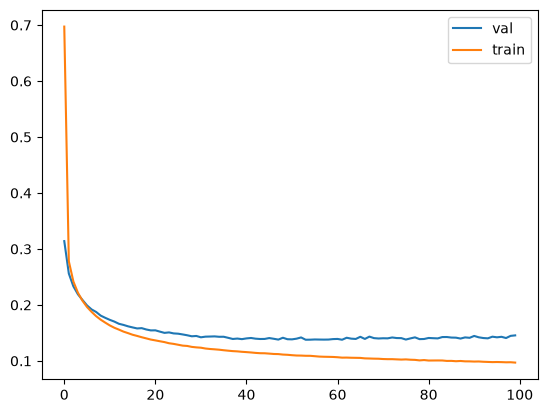

In [19]:
plt.plot(history.history['val_loss'])
plt.plot(history.history['loss'])
plt.legend(['val', 'train'])

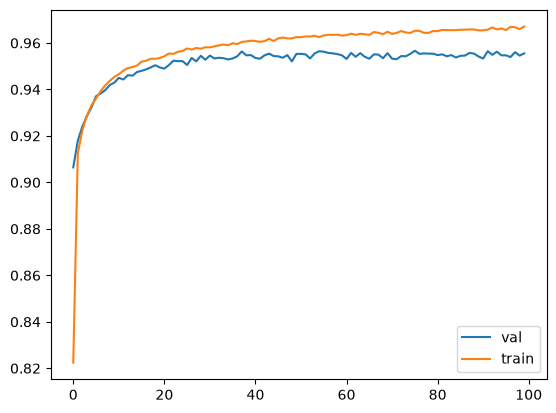

In [18]:
plt.plot(history.history['val_accuracy'])
plt.plot(history.history['accuracy'])
plt.legend(['val', 'train'])

# Metrics

In [20]:
loss, accuracy_score = model.evaluate(x_test, y_test)

375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9513 - loss: 0.1544
